# Background cutflow

Run this notebook on LPC using the same Python environment as `Cutflow_COFFEA_RUN.ipynb`. It reads the existing output; it does not rerun event processing.

The plot shows the **total expected background yield** after each cumulative cut, not raw simulated counts. The all-events, MET-filter and trigger values come from the slim stream; subsequent values come from the full stream. `passHLT` is omitted because it is a production preselection count rather than another analysis cut.


In [1]:
from pathlib import Path
import math
import matplotlib.pyplot as plt
from coffea import util

# Change this path if you move the saved output.
coffea_path = Path(
    "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/"
    "python_analysis/coffea/SlimPlusMerged2026/Bkg_cutflow.coffea"
)

if not coffea_path.is_file():
    raise FileNotFoundError(coffea_path)

loaded = util.load(str(coffea_path))
# Runner with savemetrics=True can return (analysis output, metrics).
output = loaded[0] if isinstance(loaded, tuple) else loaded
if not isinstance(output, dict) or "cutflow_cts" not in output:
    raise ValueError("Expected an analysis output dictionary containing cutflow_cts.")
print(f"Loaded: {coffea_path}")


Loaded: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/SlimPlusMerged2026/Bkg_cutflow.coffea


## Combine the saved yields

Use `cutflow_cts` for full-stream yields and `cutflow_cts_slim` for the early cuts. Match entries by sample name before adding them, so full and slim populations are never double counted. Stop if any required sample/cut is missing rather than silently replacing it with zero. Cut labels come from the saved output, so they describe the run that produced this file.


In [2]:
full = output["cutflow_cts"]
slim = output.get("cutflow_cts_slim", {})
samples = sorted(full)
if not samples or any(not name.startswith("bkg_") or name.endswith("__slim") for name in samples):
    raise ValueError("Expected background-only results keyed by base sample names.")

# Every sample must contain the same configured analysis cuts.
cut_ids = sorted(
    {key for values in full.values() for key in values
     if key.startswith("cut") and key[3:].isdigit()},
    key=lambda key: int(key[3:]),
)
if cut_ids[:2] != ["cut1", "cut2"]:
    raise ValueError("Expected cut1 (MET filters), then cut2 (trigger); check the production configuration.")

stages = ["all"] + cut_ids
labels = []
yields = []
for stage in stages:
    source = slim if stage in ("cut1", "cut2") else full
    missing = [name for name in samples if stage not in source.get(name, {})]
    if missing:
        raise ValueError(f"Missing {stage} for {missing}. Check slim processing and sample pairing.")
    value = sum(float(source[name][stage]) for name in samples)
    if not math.isfinite(value):
        raise ValueError(f"Non-finite yield at {stage}.")
    yields.append(value)
    descriptions = output.get("cutDesc_slim", {}) if stage in ("cut1", "cut2") else output.get("cutDesc", {})
    label = str(descriptions.get(stage, stage)).split("@")[0].strip()
    labels.append("All events" if stage == "all" else label)

print(f"Combined {len(samples)} background samples across {len(stages)} stages.")


Combined 29 background samples across 10 stages.


## Plot the total background cutflow

Every point is annotated with its expected yield. The automatic logarithmic scale makes large changes in yield visible; if any yield is zero or negative, a linear scale is used instead. Numbers use six significant figures for readability. No files are saved automatically.

These yields follow the processor's definition: cross section × luminosity × surviving generator-weight fraction. Weight corrections applied only to `eventWgt` are not included in this cutflow.


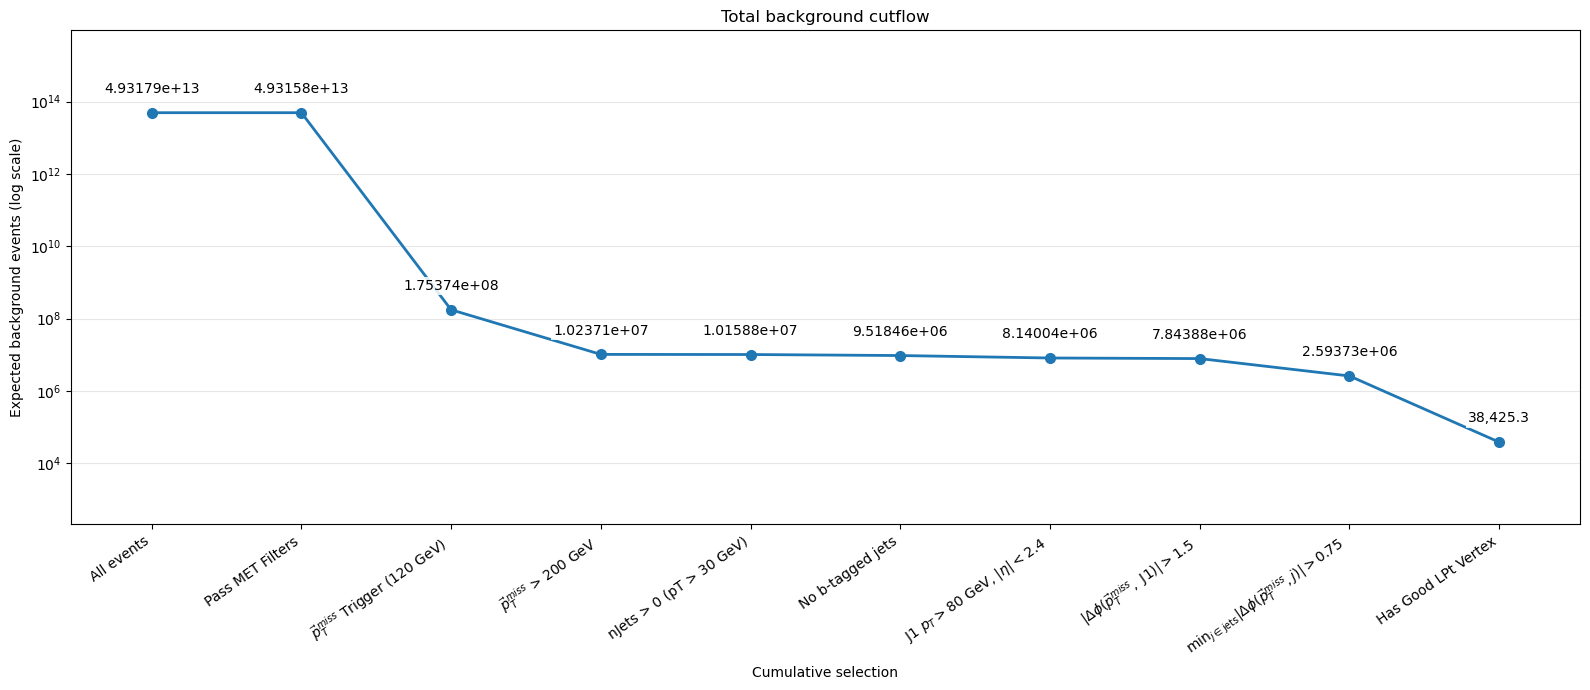

In [3]:
fig, ax = plt.subplots(figsize=(16, 7))
x = list(range(len(stages)))
ax.plot(x, yields, marker="o", linewidth=2, markersize=7, color="tab:blue")

use_log = all(value > 0 for value in yields)
if use_log:
    ax.set_yscale("log")

for position, value in zip(x, yields):
    ax.annotate(
        f"{value:,.6g}", (position, value), xytext=(0, 12),
        textcoords="offset points", ha="center", va="bottom", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5),
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=10)
ax.set_ylabel("Expected background events" + (" (log scale)" if use_log else ""))
ax.set_xlabel("Cumulative selection")
ax.set_title("Total background cutflow")
ax.grid(axis="y", which="major", alpha=0.3)
ax.margins(x=0.06, y=0.25)
fig.tight_layout()
plt.show()


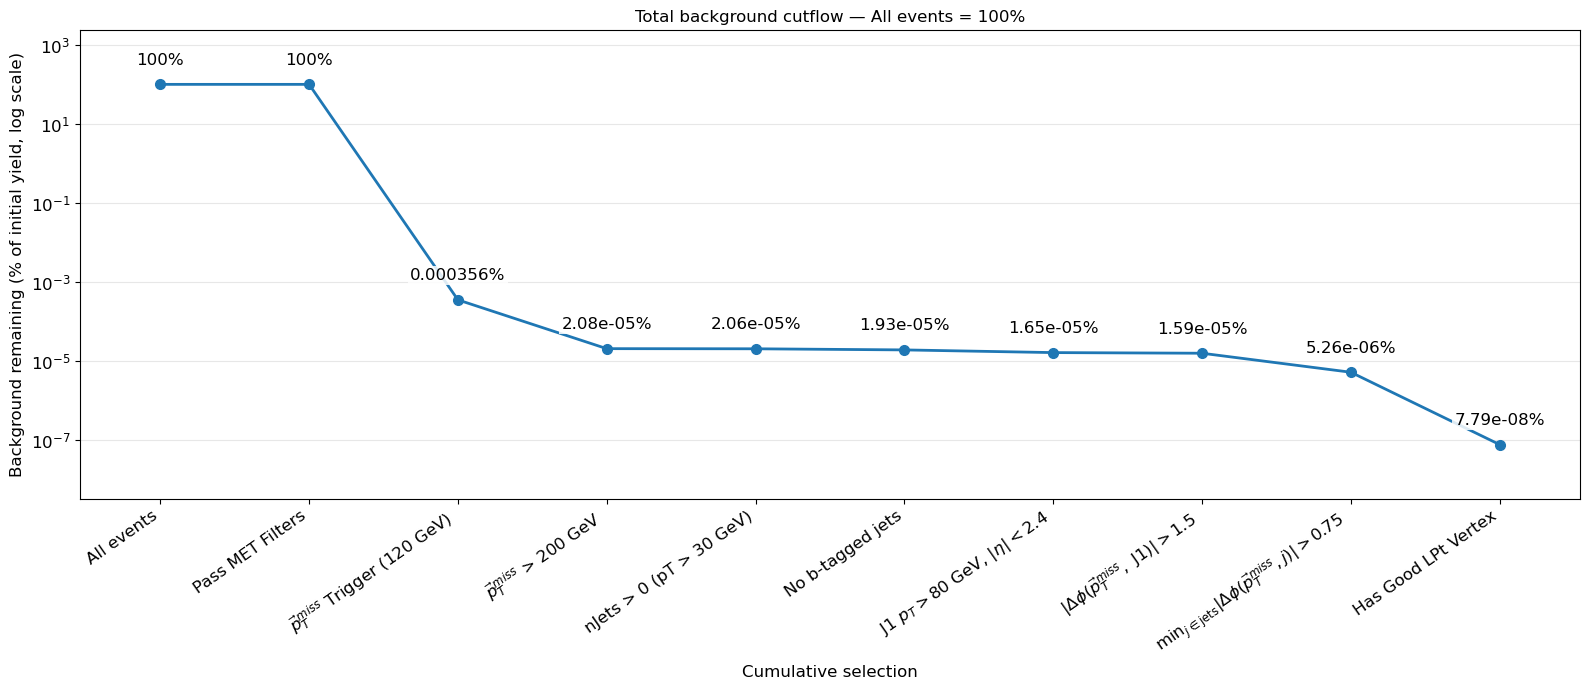

In [4]:
initial_yield = yields[stages.index("all")]

if initial_yield <= 0:
    raise ValueError("The initial background yield must be positive.")

percentages = [100 * value / initial_yield for value in yields]

if any(value <= 0 for value in percentages):
    raise ValueError("A log axis requires strictly positive percentages.")

fig, ax = plt.subplots(figsize=(16, 7))
x = list(range(len(stages)))

ax.plot(
    x, percentages,
    marker="o", linewidth=2, markersize=7, color="tab:blue"
)
ax.set_yscale("log")

for position, percentage in zip(x, percentages):
    ax.annotate(
        f"{percentage:.3g}%",
        (position, percentage),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=12,
        bbox=dict(
            facecolor="white", edgecolor="none", alpha=0.85, pad=1.5
        ),
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=12)
ax.tick_params(axis="both", which="both", labelsize=12)

ax.set_ylabel(
    "Background remaining (% of initial yield, log scale)",
    fontsize=12
)
ax.set_xlabel("Cumulative selection", fontsize=12)
ax.set_title(
    "Total background cutflow — All events = 100%",
    fontsize=12
)

ax.grid(axis="y", alpha=0.3)
ax.margins(x=0.06, y=0.15)

fig.tight_layout()
plt.show()